# Notebook 07 - Stress Testing Avance & Validation

Objectif : renforcer la partie stress testing avec :
- validation metier des scenarios ;
- comparaison multi-modeles satellites ;
- backtesting walk-forward ;
- stress PD/LGD/EAD avec garde-fous economiques ;
- migration IFRS 9 par matrice de Markov ;
- comparaison des moteurs de stress testing et selection du champion ;
- ECL forward-looking uniquement comme controle IFRS 9 complementaire.


## Positionnement bancaire du notebook

**Role dans la plateforme**  
Valider la coherence metier: scenarios, sorties de stress, migration Markov, backtesting et evaluation projet.

**Lecture expert bancaire**  
Une plateforme bancaire doit etre auditable: controles, model registry, audit trail et limites de production.

**Sorties attendues**  
validation_report.md, final_banking_modeling_audit.md, model_registry, audit_log.

**Transition logique**  
Le notebook 08 presente la revue bancaire experte complete et les resultats de decision.

In [10]:
import sys
sys.path.insert(0, '..')

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

OUTPUT_DIR = Path('../outputs')
MODELS_DIR = OUTPUT_DIR / 'models'
RESULTS_DIR = OUTPUT_DIR / 'results'
RESULTS_DIR.mkdir(exist_ok=True)

sns.set_style('whitegrid')
print('Imports OK')


Imports OK


## 1. Validation metier des scenarios

On verifie que les scenarios adverses vont dans le bon sens : chomage hausse, PIB baisse, spread hausse, et severite croissante.


In [11]:
from src.stress_scenarios import SCENARIOS, SCENARIO_LABELS, validate_scenario_design

scenario_design = validate_scenario_design()
display(scenario_design)
print('Sauvegarde : outputs/results/scenario_design_validation.csv')


,scenario_key,scenario,scenario_type,narrative,UNRATE_delta,GDP_delta,HY_SPREAD_delta,FEDFUNDS_delta,CPI_delta,severity_score,pd_lift_floor,economically_adverse
0,adverse,Adverse,macro,Ralentissement macroeconomique general avec ha...,2.5,-2.5,2.0,1.00,1.0,0.332,1.597,True
1,severe,Severe,macro,Scenario macro severe combinant contraction PI...,4.0,-3.5,2.0,1.00,1.5,0.487,1.877,True
2,rate_shock,Choc Taux,taux,"Hausse brutale des taux et de l'inflation, pre...",1.0,-1.5,3.0,3.00,3.0,0.266,1.479,True
3,market_2018,Choc Marche 2018,marche,Stress marche modere centre sur les spreads cr...,-0.1,0.0,1.8,-0.10,-0.1,0.024,1.043,True
4,ukraine_2022,Inflation Ukraine 2022,geopolitique_inflation,Choc inflation/geopolitique: taux et prix elev...,-0.3,-0.1,2.2,1.60,6.0,0.133,1.238,True
5,crisis_2008,Crise 2008,historique,"Rejeu de la crise financiere mondiale, scenari...",6.0,-6.3,15.0,-2.25,-2.4,0.898,2.616,True
6,covid_2020,Crise COVID-19,historique,"Choc sanitaire extreme, rupture rapide activit...",10.7,-11.0,5.3,-2.25,-1.8,1.173,3.112,True


Sauvegarde : outputs/results/scenario_design_validation.csv


## 2. Re-entrainement multi-modeles satellites et backtesting

On recompare OLS, Ridge, LASSO, ElasticNet, RandomForestReg, GradientBoostingReg et XGBoostReg si disponible. Le choix champion tient compte du RMSE mais aussi de la coherence economique.


In [12]:
from src.data_prep import load_macro_data
from src.satellite_models import (
    compute_quarterly_default_rate, merge_macro_quarterly,
    train_satellite_pd, satellite_walk_forward_validation,
    MACRO_PD_VARS
)

df_min = pd.read_parquet(OUTPUT_DIR / 'loan_clean.parquet', columns=['default_flag', 'issue_d', 'LGD', 'EAD'])
macro = load_macro_data()
dr_quarterly = compute_quarterly_default_rate(df_min)
sat_data = merge_macro_quarterly(dr_quarterly, macro)
macro_vars = [v for v in MACRO_PD_VARS if v in sat_data.columns]

sat_pd_models, sat_pd_results = train_satellite_pd(sat_data, macro_vars, val_start='2015', save=True)
display(sat_pd_results.sort_values(['economic_ok', 'RMSE'], ascending=[False, True]))

wf = satellite_walk_forward_validation(sat_data, macro_vars, save=True)
display(wf.groupby('Model')[['MAE', 'RMSE', 'n_folds']].first().sort_values('RMSE'))


[load_macro_data] 315 points mensuels, colonnes : ['UNRATE', 'FEDFUNDS', 'CPI', 'GDPC1', 'GDP', 'DRCCLACBS', 'HY_SPREAD', 'GDPC1_growth', 'CPI_change']
[compute_quarterly_default_rate] 47 trimestres — DR range: 0.03% → 29.56%
  [merge_macro_quarterly] Cible DR recalibrée via DRCCLACBS (facteur ×4.25) → range 0.090-0.284
[merge_macro_quarterly] 47 observations | Prédicteurs disponibles : ['UNRATE', 'GDPC1_growth', 'FEDFUNDS', 'HY_SPREAD', 'CPI_change']
  OLS      → R²_adj=-29.6069 | RMSE=0.0311 | DW=0.092 ✗ Problème autocorrélation
  Ridge    → R²_adj=-17.9050 | RMSE=0.0245 | DW=0.140
  LASSO    → R²_adj=-20.5208 | RMSE=0.0261 | 4/5 vars sélectionnées
  ElasticNet -> RMSE=0.0286
  RF-Reg   -> RMSE=0.0648
  GB-Reg   -> RMSE=0.0654
  XGB-Reg  -> RMSE=0.0656
  [WARN] Probit échoué : endog must be binary, either 0 or 1

✓ Modèle satellite PD champion : Ridge (RMSE=0.0245)


,R²,R²_adj,RMSE,MAE,AIC,BIC,DW,DW_ok,DR_base_check,DR_shock_check,economic_ok,stress_lift_check
Model,,,,,,,,,,,,
Ridge,-11.6034,-17.9050,0.0245,0.0212,NaN,NaN,0.140,✗ Problème autocorrélation,0.1114,0.2745,True,2.4645
LASSO,-13.3472,-20.5208,0.0261,0.0230,NaN,NaN,0.123,✗ Problème autocorrélation,0.1099,0.2763,True,2.5146
ElasticNet,-16.2219,-24.8328,0.0286,0.0255,NaN,NaN,0.105,✗ Problème autocorrélation,0.1081,0.2790,True,2.5802
OLS,-19.4046,-29.6069,0.0311,0.0280,-132.0,-123.3,0.092,✗ Problème autocorrélation,0.1064,0.2813,True,2.6425
RandomForestReg,-87.3823,-131.5734,0.0648,0.0608,NaN,NaN,0.066,✗ Problème autocorrélation,0.1653,0.2166,True,1.3102
GradientBoostingReg,-89.2783,-134.4174,0.0654,0.0614,NaN,NaN,0.069,✗ Problème autocorrélation,0.1625,0.2060,True,1.2673
XGBoostReg,-89.7727,-135.1590,0.0656,0.0609,NaN,NaN,0.092,✗ Problème autocorrélation,0.1574,0.2138,True,1.3579


,MAE,RMSE,n_folds
Model,,,
OLS,0.023741,0.028041,30
ElasticNet,0.023831,0.028043,30
LASSO,0.024189,0.029112,30
Ridge,0.024211,0.029223,30


## 3. Stress ECL avec garde-fous economiques

Le modele satellite donne un lift statistique. Si ce lift est incoherent avec un scenario adverse, un plancher economique base sur la severite macro est applique.


In [13]:
from src.stress_scenarios import compute_stress_ecl, compute_forward_looking_summary, ACTIVE_STRESS_SCENARIOS

POST_ORIGINATION_COLS = {
    'last_pymnt_d', 'out_prncp', 'total_rec_prncp', 'total_pymnt',
    'recoveries', 'collection_recovery_fee', 'loan_status'
}

def get_origination_pd_features(df):
    """Local PD feature selector used to avoid module import issues."""
    preferred = [
        'grade_num', 'subgrade_num', 'dti', 'revol_util', 'int_rate',
        'delinq_2yrs', 'log_annual_inc', 'credit_age_months', 'pub_rec',
        'open_acc', 'term_months', 'emp_length_num', 'verif_status_num',
        'ho_RENT', 'ho_OWN', 'UNRATE', 'GDPC1_growth', 'FEDFUNDS',
        'HY_SPREAD', 'CPI_change'
    ]
    return [c for c in preferred if c in df.columns]

df = pd.read_parquet(OUTPUT_DIR / 'loan_clean.parquet')
df_ecl = pd.read_parquet(OUTPUT_DIR / 'ecl_baseline.parquet')
df['PD_pred'] = df_ecl['PD_pred'].values
df['ECL_ifrs9'] = df_ecl['ECL_ifrs9'].values
pd_results = pd.read_csv(MODELS_DIR / 'pd_model_comparison.csv', index_col=0)
pd_champion_name = pd_results['AUC-ROC'].idxmax().lower()
pd_champion = joblib.load(MODELS_DIR / f'pd_model_{pd_champion_name}.pkl')
features = list(getattr(pd_champion, 'feature_names_in_', get_origination_pd_features(df)))


sat_results = pd.read_csv(MODELS_DIR / 'satellite_pd_comparison.csv', index_col=0)
eligible = sat_results[sat_results['economic_ok'] == True] if 'economic_ok' in sat_results.columns else sat_results.iloc[0:0]
sat_champion = (eligible['RMSE'].idxmin() if len(eligible) else sat_results['RMSE'].idxmin())
sat_features = joblib.load(MODELS_DIR / 'satellite_pd_features.pkl')
sat_models = joblib.load(MODELS_DIR / 'satellite_pd_models.pkl')

scenarios_to_run = ACTIVE_STRESS_SCENARIOS
stressed_results, summary_df = compute_stress_ecl(
    df, pd_champion, features, sat_models, sat_features, sat_champion,
    scenarios=scenarios_to_run,
)
display(summary_df)

# Controle IFRS 9 complementaire, distinct du choix du modele de stress
fl = compute_forward_looking_summary(df['ECL_ifrs9'].sum()/1e6, summary_df)
display(fl)



→ Scénario : Adverse
  ECL stressed : $7,764.1 M (×2.04 vs baseline)

→ Scénario : Severe
  ECL stressed : $8,431.2 M (×2.22 vs baseline)

→ Scénario : Choc Taux
  ECL stressed : $8,726.4 M (×2.29 vs baseline)

→ Scénario : Choc Marche 2018
  ECL stressed : $4,132.8 M (×1.09 vs baseline)

→ Scénario : Inflation Ukraine 2022
  ECL stressed : $6,252.5 M (×1.64 vs baseline)

→ Scénario : Crise 2008
  ECL stressed : $9,589.2 M (×2.52 vs baseline)

→ Scénario : Crise COVID-19
  ECL stressed : $10,043.0 M (×2.64 vs baseline)

✓ Résultats sauvegardés : C:\Users\user\Documents\pfafinal\projet_Far7ti\outputs\results\stress_ecl_summary.csv


,Scenario,ECL_stressed_M$,ECL_baseline_M$,ΔECL_M$,ECL_lift,Coverage_%,PD_baseline_%,PD_stressed_%,PD_final_lift,PD_model_lift,PD_floor_lift,Severity_score,LGD_stressed_%,EAD_Mrd$,Coherent_stress
0,Adverse,7764.06,3803.04,3961.03,2.04,22.83,45.27,83.22,2.087,2.087,1.597,0.332,66.25,35.19,True
1,Severe,8431.24,3803.04,4628.20,2.22,24.79,45.27,88.57,2.464,2.464,1.877,0.487,67.57,35.70,True
2,Choc Taux,8726.36,3803.04,4923.32,2.29,25.66,45.27,86.08,2.269,2.269,1.479,0.266,72.48,35.36,True
3,Choc Marche 2018,4132.79,3803.04,329.75,1.09,12.15,45.27,48.33,1.068,1.068,1.043,0.024,60.39,34.00,True
4,Inflation Ukraine 2022,6252.47,3803.04,2449.43,1.64,18.39,45.27,66.06,1.469,1.469,1.238,0.133,66.28,34.55,True
5,Crise 2008,9589.22,3803.04,5786.18,2.52,28.20,45.27,93.37,3.106,3.106,2.616,0.898,73.34,36.04,True
6,Crise COVID-19,10042.99,3803.04,6239.95,2.64,29.53,45.27,96.10,3.841,3.841,3.112,1.173,71.82,37.64,True


,scenario_key,Scenario,weight,ECL_M$,weighted_ECL_M$
0,baseline,Baseline,0.40,3803.037876,1521.21515
1,adverse,Adverse,0.35,7764.060000,2717.42100
2,severe,Severe,0.25,8431.240000,2107.81000
3,forward_looking,ECL Forward-Looking,1.00,6346.446150,6346.44615


## 4. Validation des sorties de stress


,Scenario,ECL_lift_ge_1,Delta_ECL_non_negative,PD_stressed_ge_baseline,PD_lift_ge_floor,validation_status
0,Adverse,True,True,True,True,OK
1,Severe,True,True,True,True,OK
2,Choc Taux,True,True,True,True,OK
3,Choc Marche 2018,True,True,True,True,OK
4,Inflation Ukraine 2022,True,True,True,True,OK
5,Crise 2008,True,True,True,True,OK
6,Crise COVID-19,True,True,True,True,OK


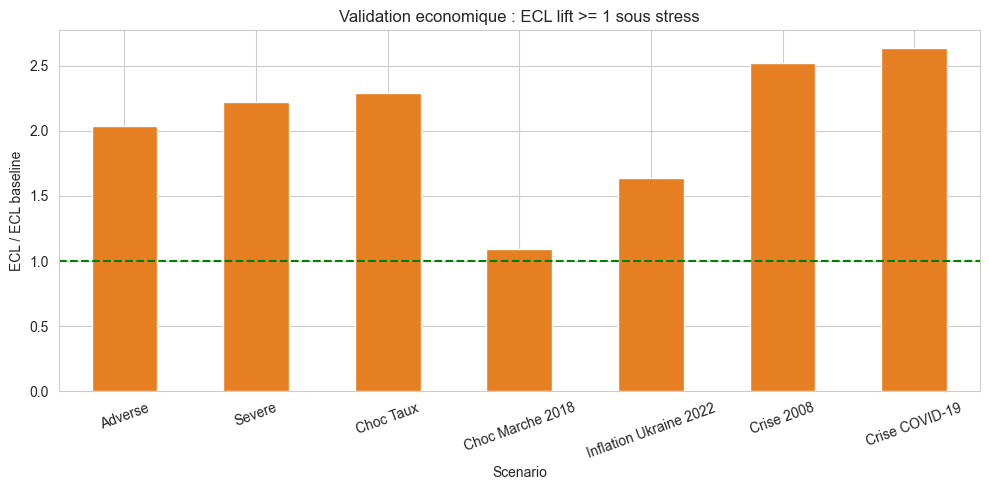

In [14]:
from src.stress_scenarios import validate_stress_outputs

stress_validation = validate_stress_outputs(summary_df)
display(stress_validation)

fig, ax = plt.subplots(figsize=(10, 5))
summary_df.plot(kind='bar', x='Scenario', y='ECL_lift', ax=ax, color='#e67e22', legend=False)
ax.axhline(1.0, color='green', linestyle='--')
ax.set_title('Validation economique : ECL lift >= 1 sous stress')
ax.set_ylabel('ECL / ECL baseline')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 5. Migration IFRS 9 par matrice de Markov


,scenario,severity_score,S1_to_S2_%,S1_to_S3_%,S2_to_S3_%,S3_maintained_%,n_migrated
0,adverse,0.332,9.8,2.3,26.3,97.7,253375
1,severe,0.487,11.4,2.9,29.7,98.0,296205
2,rate_shock,0.266,9.2,2.1,24.8,97.5,235231
3,market_2018,0.024,6.7,1.1,19.5,97.0,168584
4,ukraine_2022,0.133,7.8,1.5,21.9,97.3,198486
5,crisis_2008,0.898,15.5,4.6,38.8,98.8,409423
6,covid_2020,1.173,18.2,5.7,44.8,99.3,485285


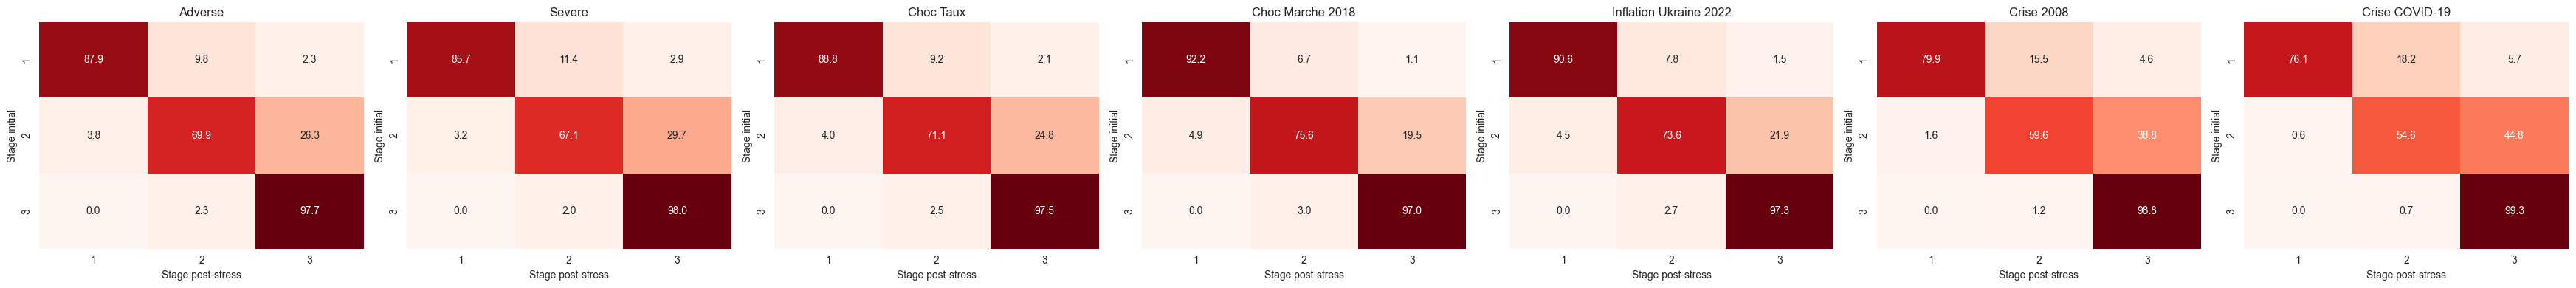

In [15]:
from src.stress_scenarios import compute_markov_stage_migration

markov_stats = []
markov_transitions = {}
for sc_name, df_s in stressed_results.items():
    df_for_mig = df.copy()
    df_for_mig['PD_stressed'] = df_s['PD_stressed'].values
    migrated, stats, transition = compute_markov_stage_migration(df_for_mig, scenarios_to_run[sc_name], sc_name)
    markov_stats.append(stats)
    markov_transitions[sc_name] = transition

markov_df = pd.DataFrame(markov_stats)
markov_df.to_csv(RESULTS_DIR / 'stage_migration_markov_summary.csv', index=False)
display(markov_df)

fig, axes = plt.subplots(1, len(markov_transitions), figsize=(5*len(markov_transitions), 4))
if len(markov_transitions) == 1:
    axes = [axes]
for ax, (sc_name, transition) in zip(axes, markov_transitions.items()):
    sns.heatmap(transition, annot=True, fmt='.1f', cmap='Reds', ax=ax, cbar=False)
    ax.set_title(SCENARIO_LABELS.get(sc_name, sc_name))
    ax.set_xlabel('Stage post-stress')
    ax.set_ylabel('Stage initial')
plt.tight_layout()
plt.show()


## 6. Validation du modele champion de stress testing

Cette section verifie que le projet ne se limite pas au forward-looking : le modele de stress retenu vient d'une comparaison de moteurs concurrents.


In [16]:
from src.stress_model_comparison import compare_stress_testing_models
from src.stress_scenarios import SCENARIO_2008

stress_model_scores, stress_champion = compare_stress_testing_models(
    df,
    scenario=SCENARIO_2008,
    scenario_name='crisis_2008',
    satellite_model=sat_models,
    satellite_features=sat_features,
    satellite_champion=sat_champion,
    save=True,
)

print(f'Champion stress testing : {stress_champion}')
display(stress_model_scores)

required_cols = {'model_name', 'final_score', 'economic_coherent', 'ECL_lift'}
assert required_cols.issubset(stress_model_scores.columns)
assert stress_model_scores.iloc[0]['model_name'] == stress_champion
assert bool(stress_model_scores.iloc[0]['economic_coherent'])


Champion stress testing : deterministic_sensitivity


,model_name,ECL_stressed_M$,ECL_lift,PD_baseline_%,PD_stressed_%,PD_lift,LGD_stressed_%,EAD_stressed_M$,observed_DR_error,economic_coherent,backtesting_score,economic_score,temporal_stability_score,ecl_precision_score,interpretability_score,final_score
0,deterministic_sensitivity,9323.616,2.4516,45.274,90.112,1.9904,73.34,36044.461,0.833419,True,0.037677,1.0,0.85,0.037677,0.95,0.529455
2,markov_stage_migration,12966.041,3.4094,45.274,90.112,1.9904,73.34,36044.461,0.833419,True,0.037677,1.0,0.85,0.037677,0.85,0.514455
4,hybrid_satellite_markov_floor,13174.918,3.4643,45.274,93.375,2.0624,73.34,36044.461,0.866049,True,0.000000,1.0,0.85,0.000000,0.80,0.490000
3,ml_macro_conditioned,9230.971,2.4273,45.274,88.987,1.9655,73.34,36044.461,0.822166,True,0.050670,1.0,0.85,0.050670,0.55,0.475302
1,satellite_macro,9589.220,2.5215,45.274,93.375,2.0624,73.34,36044.461,0.866049,True,0.000000,1.0,0.85,0.000000,0.70,0.475000


## 7. Pipeline final de validation bancaire et modelisation

Cette section integre les scripts finaux dans le notebook. Elle doit etre executee apres les validations precedentes pour produire les livrables finaux utilises par le rapport et le dashboard :

- comparaison finale des moteurs de stress testing ;
- evaluation globale du projet ;
- check-up bancaire/modelisation ;
- rapport de validation consolide ;
- tests metier rapides.


In [17]:
from pathlib import Path
import sys

# Rend les modules src/ et scripts/ importables, quel que soit le dossier courant de Jupyter.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path.cwd().parent
PROJECT_ROOT = PROJECT_ROOT.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.run_final_pipeline import run_final_pipeline

# Cette cellule remplace l'execution manuelle des scripts finaux.
# En executant le notebook 07, tous les resultats finaux sont regeneres pour l'application.
final_pipeline_result = run_final_pipeline(run_tests=True)
final_pipeline_result


{'stress_champion': 'deterministic_sensitivity',
 'project_evaluation_md': 'C:\\Users\\user\\Documents\\pfafinal\\projet_Far7ti\\outputs\\results\\project_evaluation.md',
 'project_evaluation_csv': 'C:\\Users\\user\\Documents\\pfafinal\\projet_Far7ti\\outputs\\results\\project_evaluation.csv',
 'final_audit_md': 'C:\\Users\\user\\Documents\\pfafinal\\projet_Far7ti\\outputs\\results\\final_banking_modeling_audit.md',
 'final_audit_csv': 'C:\\Users\\user\\Documents\\pfafinal\\projet_Far7ti\\outputs\\results\\final_banking_modeling_audit.csv',
 'validation_report_md': 'C:\\Users\\user\\Documents\\pfafinal\\projet_Far7ti\\outputs\\results\\validation_report.md',
 'dfast_like_report_md': 'C:\\Users\\user\\Documents\\pfafinal\\projet_Far7ti\\outputs\\results\\dfast_like_report.md',
 'business_tests_passed': 14}

In [18]:
from pathlib import Path
import pandas as pd

results_dir = PROJECT_ROOT / "outputs" / "results"
audit_path = results_dir / "final_banking_modeling_audit.csv"
validation_path = results_dir / "validation_report.md"
project_eval_path = results_dir / "project_evaluation.md"
stress_champion_path = results_dir / "stress_model_champion.csv"

print("Livrables finaux generes pour le dashboard :")
for p in [audit_path, validation_path, project_eval_path, stress_champion_path]:
    print(f"- {p.relative_to(PROJECT_ROOT)} : {'OK' if p.exists() else 'MANQUANT'}")

if audit_path.exists():
    final_audit = pd.read_csv(audit_path)
    display(final_audit)
else:
    print('Audit final non disponible. Reexecuter la cellule run_final_pipeline.')

print(f"Rapport de validation final: {validation_path}")


Livrables finaux generes pour le dashboard :
- outputs\results\final_banking_modeling_audit.csv : OK
- outputs\results\validation_report.md : OK
- outputs\results\project_evaluation.md : OK
- outputs\results\stress_model_champion.csv : OK


,area,control,status,observation,recommended_action
0,PD model,Discrimination champion,WATCH,"Champion RandomForest avec AUC=0.693, Gini=0.386.",Presenter comme prototype academique; renforce...
1,PD model,Stabilite population,OK,"PSI champion=0.067. Seuil usuel: <0.10 stable,...",Conserver la validation temporelle walk-forwar...
2,PD model,Calibration probabiliste,WATCH,Brier champion=0.208. Les probabilites restent...,Ajouter calibration Platt/isotonique et courbe...
3,Stress testing,Coherence ECL/PD sous stress,OK,7/7 scenarios coherents.,Conserver les controles automatiques dans vali...
4,Stress testing,Niveau PD moyen,WATCH,"PD baseline moyenne=45.27%. Niveau eleve, typi...",Expliquer que ce n'est pas un portefeuille ban...
5,Stress testing,Severite maximale,OK,Scenario le plus severe: Crise COVID-19 avec l...,Utiliser ce scenario pour commenter la sensibi...
6,Validation,Controles automatiques stress,OK,Statuts: {'OK': 7}.,Toute ligne REVIEW doit etre commentee dans le...
7,Model governance,Champion stress testing,OK,Champion scoring: deterministic_sensitivity av...,Presenter la selection comme score multi-crite...
8,Model governance,Trace champion,OK,Champion documente: {'champion_model': 'determ...,Garder ce fichier comme preuve de gouvernance ...
9,Satellite macro,Pouvoir explicatif statistique,WATCH,Meilleur R2 satellite=-11.603. Les sorties act...,Assumer le satellite comme outil de sensibilit...


Rapport de validation final: C:\Users\user\Documents\pfafinal\projet_Far7ti\outputs\results\validation_report.md


## Controle bancaire complementaire: gouvernance modele et audit trail

Cette section montre que les executions sont tracables et que les modeles ont
un statut de validation/approbation, meme dans un prototype academique.

In [19]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
registry_path = ROOT / "outputs" / "governance" / "model_registry.csv"
audit_path = ROOT / "outputs" / "governance" / "audit_log.jsonl"

if registry_path.exists():
    display(pd.read_csv(registry_path))
else:
    print("Model registry non disponible. Executer le notebook 08.")

if audit_path.exists():
    audit = pd.read_json(audit_path, lines=True)
    display(audit.tail(10))
else:
    print("Audit trail non disponible. Executer un stress run ou le notebook 08.")

,model_id,version,owner,validation_status,approval_status,last_review_date
0,PD_CHAMPION,v1.0,Risk Modeling,Validated for PFA prototype,Model Committee simulated,2026-05-08
1,SATELLITE_MACRO_PD,v1.0,Stress Testing,Backtesting required before production,Conditional approval,2026-05-08
2,BASEL_RWA_STANDARDIZED,v1.0,Regulatory Capital,Rule-based benchmark,Approved for simulation,2026-05-08


,run_id,timestamp_utc,event_type,user,parameters,outputs
0,8e6934a8-fa28-4d5b-9105-0c657ebd5c31,2026-05-08 09:24:04.403490+00:00,script_banking_expert_review,pipeline,"{'reporting_date': '2018-12-01', 'n_scenarios'...","{'worst_scenario': 'Crise COVID-19', 'expected..."
1,ef74c609-bb18-40f6-9269-5112e73343b5,2026-05-08 09:26:05.249147+00:00,script_banking_expert_review,pipeline,"{'reporting_date': '2018-12-01', 'n_scenarios'...","{'worst_scenario': 'Crise COVID-19', 'expected..."
2,84e56614-0a21-4b67-a53d-e1f31e4c5fda,2026-05-08 09:27:41.163586+00:00,script_banking_expert_review,pipeline,"{'reporting_date': '2018-12-01', 'n_scenarios'...","{'worst_scenario': 'Crise COVID-19', 'expected..."
3,a30f269e-25b9-4c9c-b599-d4e9f66ce770,2026-05-08 09:36:38.993613+00:00,script_banking_expert_review,pipeline,"{'reporting_date': '2018-12-01', 'n_scenarios'...","{'worst_scenario': 'Crise COVID-19', 'expected..."
4,0764bbd3-99a5-4454-bc25-8521348c7a45,2026-05-08 09:39:12.389378+00:00,script_banking_expert_review,pipeline,"{'reporting_date': '2018-12-01', 'n_scenarios'...","{'worst_scenario': 'Crise COVID-19', 'expected..."
5,974524fc-babc-47a5-9c90-4ddcc8203114,2026-05-08 10:20:17.442170+00:00,one_year_stress_matrix,streamlit_user,"{'scenario': 'Adverse', 'horizon_years': 1, 'c...","{'worst_scenario': 'Crise 2008', 'worst_loss_y..."


## Coherence avec la chaine IFRS 9 + Bale + stress testing

Ce notebook s'inscrit dans la chaine complete:

`Donnees -> Qualite -> PD/LGD/EAD -> ECL IFRS 9 -> Satellites macro -> Stress Y1 -> RWA/CET1 -> Decision -> Gouvernance`

Les resultats finaux de niveau bancaire sont consolides dans:

- `notebooks/08_Banking_Expert_Review.ipynb`
- `outputs/results/one_year_stress_decision_matrix.csv`
- `outputs/results/basel_capital_metrics.csv`
- `outputs/results/regulatory_segment_summary.csv`
- `outputs/results/dynamic_projection_expert.csv`

Cette coherence permet de defendre le projet a la fois comme travail de modelisation
et comme prototype de plateforme bancaire.